# EV Charging Demand Prediction & Usage Pattern Analysis
## Part 1: Data Understanding, Cleaning & Exploratory Data Analysis (EDA)

### Objectives:
- Inspect and understand the EV charging dataset (~72,000+ sessions)
- Clean anomalies, handle duplicates, correct datetime formats, and validate durations
- Analyze charging demand patterns across locations, charger types, and companies
- Uncover peak charging hours, day-of-week trends, and feature correlations

In [1]:
# Import required libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
print("Libraries loaded successfully!")

Libraries loaded successfully!


### 1. Load Raw Dataset

In [2]:
raw_path = os.path.join('..', 'data', 'raw', 'ChargingRecords.csv')
df_raw = pd.read_csv(raw_path)
print(f"Raw dataset shape: {df_raw.shape}")
df_raw.head()

Raw dataset shape: (72856, 13)

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54,2022-09-15 23:59,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01,2022-09-14 21:31,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54,2022-09-14 19:54,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32,2022-09-30 0:16,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30,2022-09-26 0:30,300,33.81


### 2. Dataset Information & Missing Value Assessment

In [3]:
print("Data Types & Non-Null Counts:")
df_raw.info()
print("\nMissing values per column:\n", df_raw.isnull().sum())
print(f"\nDuplicate rows count: {df_raw.duplicated().sum()}")

Data Types & Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 72856 entries, 0 to 72855
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UserID          72856 non-null  int64  
 1   ChargerID       72856 non-null  int64  
 2   ChargerCompany  72856 non-null  int64  
 3   Location        72856 non-null  str    
 4   ChargerType     72856 non-null  int64  
 5   StartDay        72856 non-null  str    
 6   StartTime       72856 non-null  str    
 7   EndDay          72856 non-null  str    
 8   EndTime         72856 non-null  str    
 9   StartDatetime   72856 non-null  str    
 10  EndDatetime     72856 non-null  str    
 11  Duration        72856 non-null  int64  
 12  Demand          72856 non-null  float64
dtypes: float64(1), int64(5), str(7)
memory usage: 12.5 MB

Missing values per column:
 UserID            0
ChargerID         0
ChargerCompany    0
Location          0
ChargerType       0
StartDay 


Duplicate rows count: 13


### 3. Data Cleaning Pipeline
- Deduplication
- Datetime conversion
- Duration recalculation & anomaly filtering

In [4]:
# Deduplicate
df_clean = df_raw.drop_duplicates().copy()

# Datetime parsing
df_clean['StartDatetime'] = pd.to_datetime(df_clean['StartDatetime'], errors='coerce')
df_clean['EndDatetime'] = pd.to_datetime(df_clean['EndDatetime'], errors='coerce')

# Recalculate duration in minutes
calc_duration = (df_clean['EndDatetime'] - df_clean['StartDatetime']).dt.total_seconds() / 60.0
df_clean['Duration_Mins'] = np.where(df_clean['Duration'] > 0, df_clean['Duration'], calc_duration)

# Filter realistic duration and demand records
valid_mask = (df_clean['Duration_Mins'] > 0) & (df_clean['Duration_Mins'] <= 1440) & (df_clean['Demand'] > 0)
df_clean = df_clean[valid_mask].reset_index(drop=True)

print(f"Cleaned records: {len(df_clean):,}")
df_clean[['Duration_Mins', 'Demand']].describe()

Cleaned records: 72,421


,Duration_Mins,Demand
count,72421.000000,72421.000000
mean,152.378412,17.532101
std,146.241084,13.468293
min,1.000000,0.010000
25%,41.000000,7.640000
50%,113.000000,14.200000
75%,202.000000,23.200000
max,1439.000000,97.000000


### 4. Feature Engineering
Extract hour, day, month, day of week, cyclical sine/cosine features, and classification median threshold.

In [5]:
df_clean['StartHour'] = df_clean['StartDatetime'].dt.hour
df_clean['StartDay'] = df_clean['StartDatetime'].dt.day
df_clean['StartMonth'] = df_clean['StartDatetime'].dt.month
df_clean['DayOfWeek'] = df_clean['StartDatetime'].dt.day_of_week
df_clean['DayName'] = df_clean['StartDatetime'].dt.day_name()
df_clean['IsWeekend'] = df_clean['DayOfWeek'].isin([5, 6]).astype(int)

# Cyclical hour encoding
df_clean['Hour_Sin'] = np.sin(2 * np.pi * df_clean['StartHour'] / 24.0)
df_clean['Hour_Cos'] = np.cos(2 * np.pi * df_clean['StartHour'] / 24.0)

# Classification target per project specifications: High vs Normal Demand
median_demand = float(df_clean['Demand'].median())
df_clean['High_Demand'] = (df_clean['Demand'] >= median_demand).astype(int)

print(f"Median Demand Threshold: {median_demand:.2f} kWh")
print(df_clean['High_Demand'].value_counts(normalize=True))

Median Demand Threshold: 14.20 kWh
High_Demand
1    0.500338
0    0.499662
Name: proportion, dtype: float64


### 5. Exploratory Visualizations

C:\Users\packi\AppData\Local\Temp\ipykernel_21888\1891393089.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_clean, x='Location', y='Demand', estimator=np.sum, errorbar=None, palette='Blues_r')


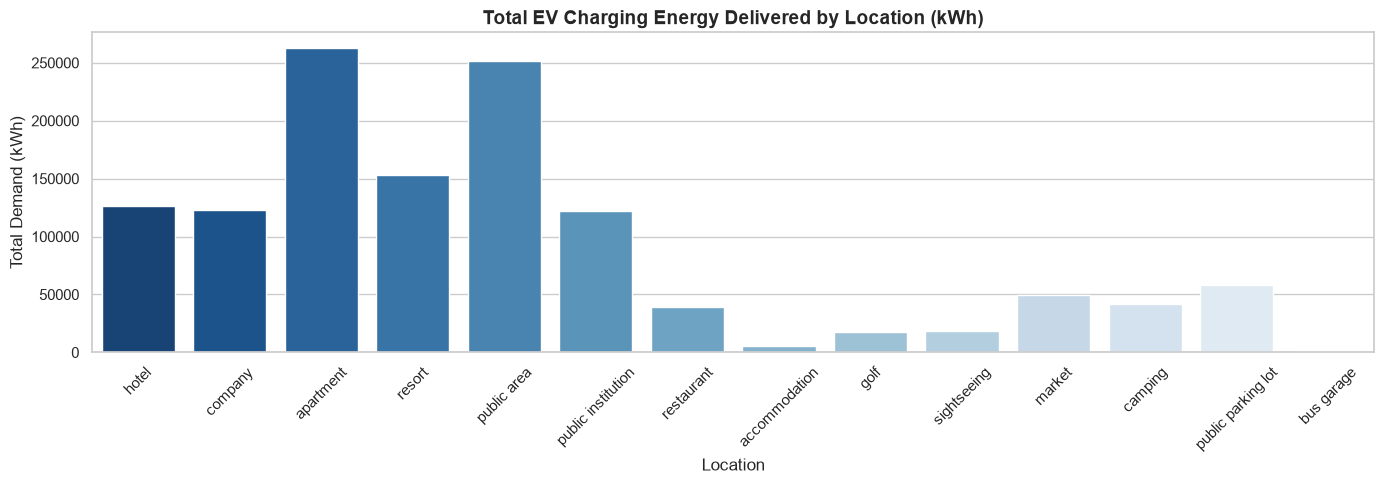

In [6]:
# 1. Demand by Location
plt.figure(figsize=(14, 5))
sns.barplot(data=df_clean, x='Location', y='Demand', estimator=np.sum, errorbar=None, palette='Blues_r')
plt.title('Total EV Charging Energy Delivered by Location (kWh)', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.ylabel('Total Demand (kWh)')
plt.tight_layout()
plt.show()

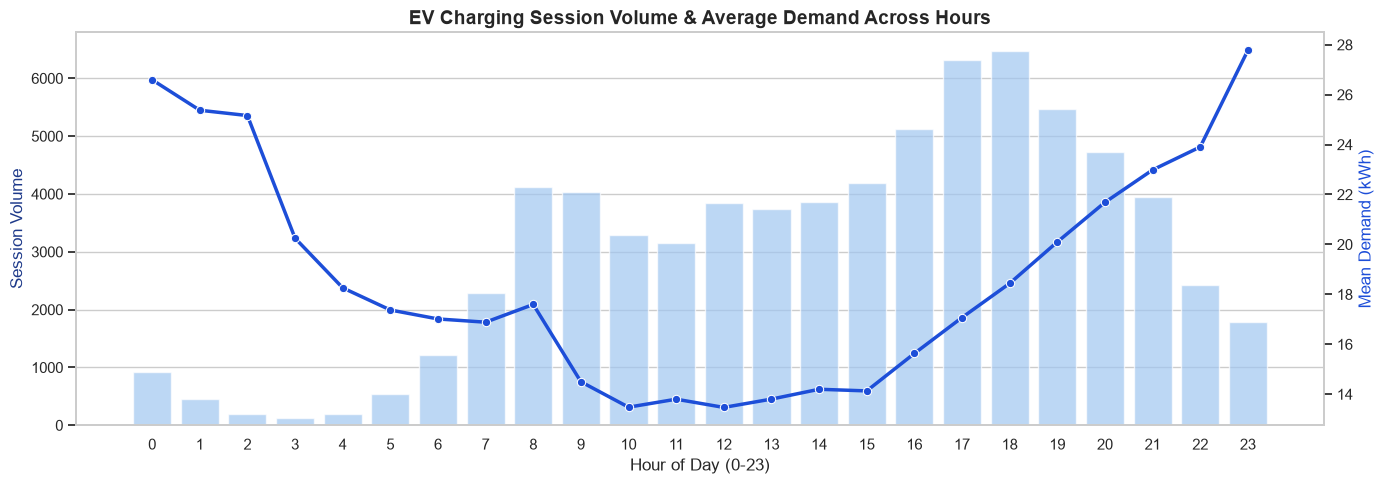

In [7]:
# 2. Hourly Charging Demand Pattern
hourly_agg = df_clean.groupby('StartHour')['Demand'].agg(['count', 'mean']).reset_index()

fig, ax1 = plt.subplots(figsize=(14, 5))
ax2 = ax1.twinx()

sns.barplot(data=hourly_agg, x='StartHour', y='count', ax=ax1, color='#93C5FD', alpha=0.7)
sns.lineplot(data=hourly_agg, x='StartHour', y='mean', ax=ax2, color='#1D4ED8', marker='o', linewidth=2.5)

ax1.set_title('EV Charging Session Volume & Average Demand Across Hours', fontsize=14, fontweight='bold')
ax1.set_xlabel('Hour of Day (0-23)')
ax1.set_ylabel('Session Volume', color='#1E3A8A')
ax2.set_ylabel('Mean Demand (kWh)', color='#1D4ED8')
plt.grid(False)
plt.tight_layout()
plt.show()

C:\Users\packi\AppData\Local\Temp\ipykernel_21888\2513335052.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='ChargerType', ax=axes[0], palette='Set2')


C:\Users\packi\AppData\Local\Temp\ipykernel_21888\2513335052.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='ChargerType', y='Demand', ax=axes[1], palette='Set2', showfliers=False)


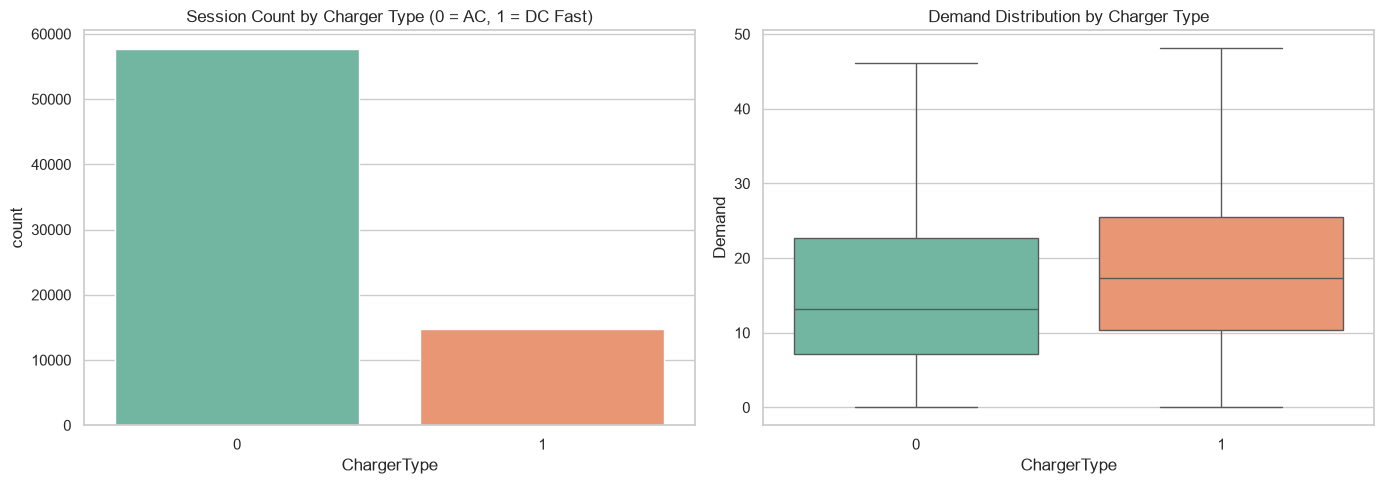

In [8]:
# 3. Charger Type Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df_clean, x='ChargerType', ax=axes[0], palette='Set2')
axes[0].set_title('Session Count by Charger Type (0 = AC, 1 = DC Fast)')

sns.boxplot(data=df_clean, x='ChargerType', y='Demand', ax=axes[1], palette='Set2', showfliers=False)
axes[1].set_title('Demand Distribution by Charger Type')
plt.tight_layout()
plt.show()